In [11]:
!pip install -q "pillow<13.0" roboflow kagglehub
!pip install -q timm>=1.0.15 albumentations>=2.0.5 onnx onnxscript onnxruntime>=1.18

In [12]:
import os, glob, json, shutil, subprocess, warnings, time
from pathlib import Path
import cv2
import yaml
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from roboflow import Roboflow
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm
from timm.data import resolve_model_data_config
import albumentations as A

warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if USE_AMP: torch.backends.cudnn.benchmark = True
print(f"🚀 Thiết bị huấn luyện: {DEVICE}")

🚀 Thiết bị huấn luyện: cuda


In [13]:
MASTER_DATA = "/kaggle/working/master_dataset"
CLASS_NORMAL = os.path.join(MASTER_DATA, "normal")
CLASS_DAMAGE = os.path.join(MASTER_DATA, "damage")

if os.path.exists(MASTER_DATA): shutil.rmtree(MASTER_DATA)
os.makedirs(CLASS_NORMAL, exist_ok=True)
os.makedirs(CLASS_DAMAGE, exist_ok=True)

counters = {"normal": 0, "damage": 0}
rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])

print("⏳ Bắt đầu tải và hợp nhất 5 bộ dữ liệu...")

# 1. Kaggle: ducnguyentien69/parcel-classification (Folder)
print("1/5. Tải Kaggle: ducnguyentien69...")
kg_path = kagglehub.dataset_download("ducnguyentien69/parcel-classification")
for root, _, files in os.walk(kg_path, followlinks=True):
    for f in files:
        if not f.lower().endswith(('.jpg', '.jpeg', '.png')): continue
        src_path = os.path.join(root, f)
        p_lower = src_path.lower().replace("\\", "/")
        if "normal" in p_lower: cat, trg = "normal", CLASS_NORMAL
        elif "damage" in p_lower: cat, trg = "damage", CLASS_DAMAGE
        else: continue
        shutil.copy2(src_path, os.path.join(trg, f"kg_{Path(src_path).parts[-3]}_{f}"))
        counters[cat] += 1

# 2. Roboflow: project-33xgh (Folder Structure)
print("2/5. Tải Roboflow: project-33xgh...")
ds2 = rf.workspace("project-33xgh").project("damaged-box-detection").version(1).download("folder")
for split in ["train", "valid", "test"]:
    split_dir = os.path.join(ds2.location, split)
    if not os.path.exists(split_dir): continue
    for cls_folder in os.listdir(split_dir):
        cls_path = os.path.join(split_dir, cls_folder)
        if not os.path.isdir(cls_path): continue
        c_low = cls_folder.lower()
        if "undamaged" in c_low: cat, trg = "normal", CLASS_NORMAL
        elif "damage" in c_low: cat, trg = "damage", CLASS_DAMAGE
        else: continue
        for img_p in glob.glob(os.path.join(cls_path, "*.*")):
            if not img_p.lower().endswith(('.jpg', '.jpeg', '.png')): continue
            shutil.copy2(img_p, os.path.join(trg, f"rf33_{split}_{Path(img_p).name}"))
            counters[cat] += 1

# 3. Roboflow: kardus (YOLOv8 - Phân loại nguyên ảnh)
print("3/5. Tải Roboflow: kardus...")
ds3 = rf.workspace("kardus").project("corrugated-box-defect").version(14).download("yolov8")
with open(os.path.join(ds3.location, "data.yaml"), "r") as f:
    cls_names3 = list(yaml.safe_load(f).get("names", []))
for split in ["train", "valid", "test"]:
    img_dir, lbl_dir = os.path.join(ds3.location, split, "images"), os.path.join(ds3.location, split, "labels")
    if not os.path.exists(img_dir): continue
    for img_p in glob.glob(os.path.join(img_dir, "*.*")):
        if not img_p.lower().endswith(('.jpg', '.jpeg', '.png')): continue
        lbl_p = os.path.join(lbl_dir, f"{Path(img_p).stem}.txt")
        has_defect = False
        if os.path.exists(lbl_p):
            with open(lbl_p, "r") as f:
                for line in f:
                    if not line.strip(): continue
                    cls_n = str(cls_names3[int(line.split()[0])]).lower()
                    if "torn" in cls_n or "wrinkle" in cls_n: has_defect = True; break
        cat, trg = ("damage", CLASS_DAMAGE) if has_defect else ("normal", CLASS_NORMAL)
        shutil.copy2(img_p, os.path.join(trg, f"rfkar_{split}_{Path(img_p).name}"))
        counters[cat] += 1

# 4. Github: chanllon (Labelme - Cắt box kèm padding 10%)
print("4/5. Tải Github: chanllon...")
REPO_DIR = "/kaggle/working/corrugated_dataset_repo"
if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/chanllon/corrugated-cardboard-boxes-dataset.git", REPO_DIR])
defect_kw = ["damage", "defect", "hole", "crush", "dent", "broken", "scratch", "bad", "tear", "press"]
for json_path in glob.glob(f"{REPO_DIR}/**/*.json", recursive=True):
    stem, folder = Path(json_path).stem, os.path.dirname(json_path)
    img_p = os.path.join(folder, f"{stem}.jpg")
    if not os.path.exists(img_p): continue
    try:
        with open(json_path, "r", encoding="utf-8") as f: data = json.load(f)
    except: continue
    shapes = data.get("shapes", [])
    if not shapes: continue
    has_dmg = any(any(k in s.get("label", "").lower() for k in defect_kw) for s in shapes)
    cat, trg = ("damage", CLASS_DAMAGE) if has_dmg else ("normal", CLASS_NORMAL)
    img = cv2.imread(img_p)
    if img is None: continue
    boxes = [s for s in shapes if "box" in s.get("label", "").lower()] or shapes
    for idx, shape in enumerate(boxes):
        pts = shape.get("points", [])
        if not pts: continue
        xs, ys = [p[0] for p in pts], [p[1] for p in pts]
        xmin, xmax, ymin, ymax = min(xs), max(xs), min(ys), max(ys)
        bw, bh = xmax - xmin, ymax - ymin
        if bw <= 0 or bh <= 0: continue
        pw, ph = bw * 0.10, bh * 0.10
        c_xmin, c_xmax = int(max(0, xmin - pw)), int(min(img.shape[1], xmax + pw))
        c_ymin, c_ymax = int(max(0, ymin - ph)), int(min(img.shape[0], ymax + ph))
        crop = img[c_ymin:c_ymax, c_xmin:c_xmax]
        if crop.size > 0:
            cv2.imwrite(os.path.join(trg, f"gh_{Path(folder).name}_{stem}_{idx}.jpg"), crop)
            counters[cat] += 1

# 5. Roboflow: kevinpahm/carton-l5tsa (YOLOv8 - Cắt box kèm padding 10%)
print("5/5. Tải Roboflow: kevinpahm/carton...")
ds5 = rf.workspace("kevinpahm").project("carton-l5tsa").version(1).download("yolov8")
with open(os.path.join(ds5.location, "data.yaml"), "r") as f:
    cls_names5 = list(yaml.safe_load(f).get("names", []))
for split in ["train", "valid", "test"]:
    img_dir, lbl_dir = os.path.join(ds5.location, split, "images"), os.path.join(ds5.location, split, "labels")
    if not os.path.exists(img_dir): continue
    for img_p in glob.glob(os.path.join(img_dir, "*.*")):
        if not img_p.lower().endswith(('.jpg', '.jpeg', '.png')): continue
        lbl_p = os.path.join(lbl_dir, f"{Path(img_p).stem}.txt")
        if not os.path.exists(lbl_p): continue
        img = cv2.imread(img_p)
        if img is None: continue
        img_h, img_w = img.shape[:2]
        
        with open(lbl_p, "r") as f:
            for idx, line in enumerate(f):
                parts = line.strip().split()
                if len(parts) < 5: continue
                cls_id = int(parts[0])
                cls_n = str(cls_names5[cls_id]).strip().lower() if cls_id < len(cls_names5) else ""
                
                # 'invalid' -> damage | 'valid-error' (hoặc khác) -> normal
                if "invalid" in cls_n: cat, trg = "damage", CLASS_DAMAGE
                else: cat, trg = "normal", CLASS_NORMAL
                
                xc, yc = float(parts[1]) * img_w, float(parts[2]) * img_h
                bw, bh = float(parts[3]) * img_w, float(parts[4]) * img_h
                pw, ph = bw * 0.10, bh * 0.10
                
                c_xmin, c_xmax = int(max(0, xc - bw/2 - pw)), int(min(img_w, xc + bw/2 + pw))
                c_ymin, c_ymax = int(max(0, yc - bh/2 - ph)), int(min(img_h, yc + bh/2 + ph))
                crop = img[c_ymin:c_ymax, c_xmin:c_xmax]
                
                if crop.size > 0:
                    cv2.imwrite(os.path.join(trg, f"rfkv_{split}_{Path(img_p).stem}_{idx}.jpg"), crop)
                    counters[cat] += 1

print(f"\n✅ GỘP DỮ LIỆU XONG: Normal={counters['normal']}, Damage={counters['damage']}")

⏳ Bắt đầu tải và hợp nhất 5 bộ dữ liệu...
1/5. Tải Kaggle: ducnguyentien69...
2/5. Tải Roboflow: project-33xgh...
loading Roboflow workspace...
loading Roboflow project...
3/5. Tải Roboflow: kardus...
loading Roboflow workspace...
loading Roboflow project...
4/5. Tải Github: chanllon...
5/5. Tải Roboflow: kevinpahm/carton...
loading Roboflow workspace...
loading Roboflow project...

✅ GỘP DỮ LIỆU XONG: Normal=5177, Damage=7415


In [14]:
IMG_SIZE = 256
BATCH_SIZE = 48

all_paths, all_labels = [], []
for p in Path(MASTER_DATA).rglob("*.jpg"):
    all_paths.append(str(p))
    all_labels.append(0 if "normal" in p.parts else 1)

# Chia Train 70%, Test 30% -> Từ Test chia đôi ra Val 15%, Test 15%
X_train, X_temp, y_train, y_temp = train_test_split(
    all_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f"📊 Tập dữ liệu: Train={len(X_train)} | Val={len(X_val)} | Test={len(X_test)}")

train_tf = A.Compose([
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.6, 1.0)),
    A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5), A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.5),
    A.OneOf([A.RandomBrightnessContrast(), A.CLAHE(clip_limit=2.0)], p=0.6),
    A.GaussNoise(std_range=(0.01, 0.05), p=0.2)
])
eval_tf = A.Compose([A.Resize(height=IMG_SIZE, width=IMG_SIZE, interpolation=cv2.INTER_AREA)])

class BoxDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.tf = paths, labels, transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        img = cv2.cvtColor(cv2.imread(self.paths[idx]), cv2.COLOR_BGR2RGB)
        img = self.tf(image=img)["image"]
        x = torch.from_numpy(img.transpose(2, 0, 1)).float().div(255.0)
        y = torch.tensor(self.labels[idx], dtype=torch.long)
        return x, y

train_loader = DataLoader(BoxDataset(X_train, y_train, train_tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(BoxDataset(X_val, y_val, eval_tf), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(BoxDataset(X_test, y_test, eval_tf), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

📊 Tập dữ liệu: Train=8814 | Val=1889 | Test=1889


In [15]:
class PackagingNet(nn.Module):
    def __init__(self, model_name="mobilenetv4_conv_medium.e500_r256_in1k", pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0)
        dc = resolve_model_data_config(self.backbone)
        
        self.register_buffer("mean", torch.tensor(dc["mean"]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(dc["std"]).view(1, 3, 1, 1))
        
        with torch.no_grad():
            self.backbone.eval()
            nf = self.backbone.forward_head(
                self.backbone.forward_features(torch.zeros(1, 3, 128, 128)), pre_logits=True
            ).shape[1]
            
        self.drop = nn.Dropout(0.2)
        self.head = nn.Linear(nf, 2)

    def forward(self, x):
        x = (x - self.mean) / self.std
        f = self.backbone.forward_head(self.backbone.forward_features(x), pre_logits=True)
        return self.head(self.drop(f))

model = PackagingNet().to(DEVICE)
print(f"🏗️ Mô hình MobileNetV4. Số tham số: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")

🏗️ Mô hình MobileNetV4. Số tham số: 8.44 M


====================================== TRAINING START ======================================
Epoch    | Train Loss Train Acc  | Val Loss   Val Acc  Prec     Rec      mAP     
-----------------------------------------------------------------------------------------------


Epoch 1/100 [Train]:   0%|          | 0/184 [00:00<?, ?it/s]

Epoch 1/100 [Val]  :   0%|          | 0/40 [00:00<?, ?it/s]

1/100    | 0.3882     0.8493     | 0.3131     0.9021   0.9106   0.9245   0.9703  


Epoch 2/100 [Train]:   0%|          | 0/184 [00:00<?, ?it/s]

Epoch 2/100 [Val]  :   0%|          | 0/40 [00:00<?, ?it/s]

... (291 outputs left out)

99/100    | 0.1248     0.9971     | 0.1891     0.9730   0.9784   0.9757   0.9859  


Epoch 100/100 [Train]:   0%|          | 0/184 [00:00<?, ?it/s]

Epoch 100/100 [Val]  :   0%|          | 0/40 [00:00<?, ?it/s]

100/100    | 0.1236     0.9977     | 0.1924     0.9719   0.9783   0.9739   0.9857  
✅ Đã lưu lịch sử huấn luyện vào: /kaggle/working/training_history.csv
====================================== TRAINING END ======================================


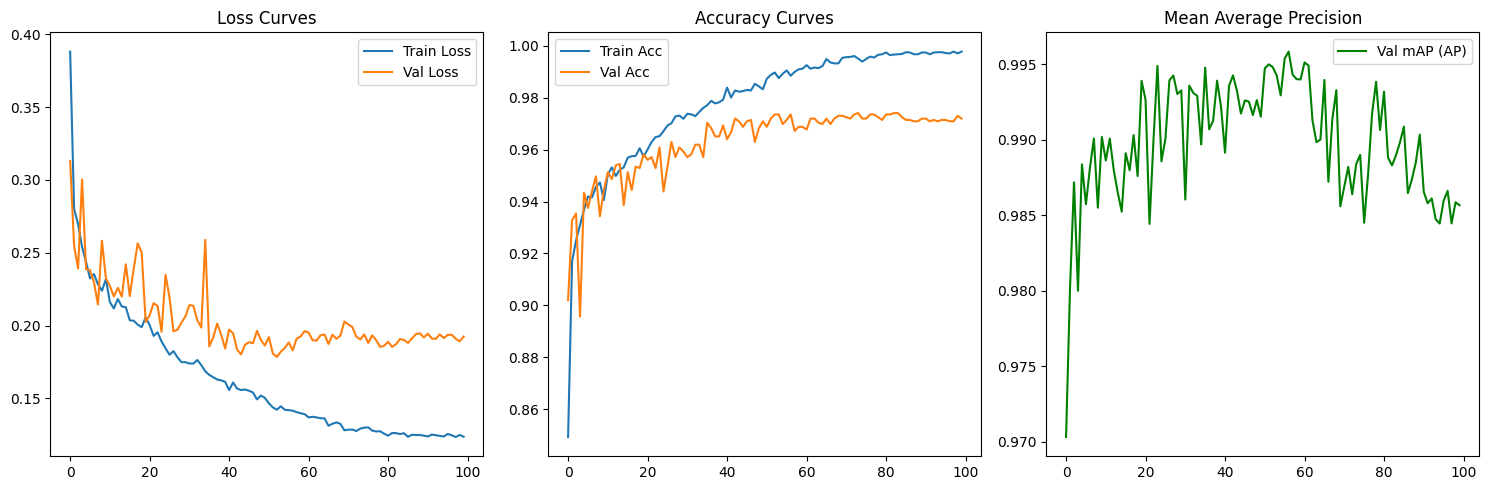

In [16]:
from tqdm.auto import tqdm
import pandas as pd

EPOCHS = 100
LR = 5e-4
PATIENCE = 5

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

history = {"epoch": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_prec": [], "val_rec": [], "val_mAP": []}
best_ap, early_stop_counter = 0.0, 0

best_model_path = "/kaggle/working/best_model.pth"
last_model_path = "/kaggle/working/last_model.pth"
csv_history_path = "/kaggle/working/training_history.csv"

print("====================================== TRAINING START ======================================")
print(f"{'Epoch':<8} | {'Train Loss':<10} {'Train Acc':<10} | {'Val Loss':<10} {'Val Acc':<8} {'Prec':<8} {'Rec':<8} {'mAP':<8}")
print("-" * 95)

for epoch in range(EPOCHS):
    # -------- TRAINING --------
    model.train()
    run_loss, correct, total = 0.0, 0, 0
    
    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=False)
    for x, y in train_pbar:
        x, y = x.to(DEVICE), y.to(DEVICE)
        
        optimizer.zero_grad()
        with torch.autocast("cuda", enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        loss_item = loss.item()
        run_loss += loss_item * x.size(0)
        preds = torch.argmax(logits, dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)
        
        train_pbar.set_postfix(loss=f"{loss_item:.4f}")
        
    train_loss, train_acc = run_loss / total, correct / total
    
    # -------- VALIDATION --------
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []
    
    val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]  ", leave=False)
    with torch.no_grad():
        for x, y in val_pbar:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast("cuda", enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)
                
            val_loss += loss.item() * x.size(0)
            probs = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            
            val_correct += (preds == y.cpu().numpy()).sum()
            val_total += y.size(0)
            
            all_preds.extend(preds)
            all_labels.extend(y.cpu().numpy())
            all_probs.extend(probs)
            
    v_loss, v_acc = val_loss / val_total, val_correct / val_total
    v_prec = precision_score(all_labels, all_preds, zero_division=0)
    v_rec = recall_score(all_labels, all_preds, zero_division=0)
    v_ap = average_precision_score(all_labels, all_probs)
    
    scheduler.step()
    
    # Lưu history
    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(v_loss); history["val_acc"].append(v_acc)
    history["val_prec"].append(v_prec); history["val_rec"].append(v_rec); history["val_mAP"].append(v_ap)
    
    log_str = (f"{epoch+1}/{EPOCHS:<6} | "
               f"{train_loss:<10.4f} {train_acc:<10.4f} | "
               f"{v_loss:<10.4f} {v_acc:<8.4f} {v_prec:<8.4f} {v_rec:<8.4f} {v_ap:<8.4f}")
    print(log_str)
    
    torch.save(model.state_dict(), last_model_path)
    
    if v_ap > best_ap:
        best_ap = v_ap
        torch.save(model.state_dict(), best_model_path)

# 3. Xuất history ra CSV
pd.DataFrame(history).to_csv(csv_history_path, index=False)
print(f"✅ Đã lưu lịch sử huấn luyện vào: {csv_history_path}")

print("====================================== TRAINING END ======================================")

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.plot(history["train_loss"], label="Train Loss"); plt.plot(history["val_loss"], label="Val Loss")
plt.title("Loss Curves"); plt.legend()
plt.subplot(1, 3, 2)
plt.plot(history["train_acc"], label="Train Acc"); plt.plot(history["val_acc"], label="Val Acc")
plt.title("Accuracy Curves"); plt.legend()
plt.subplot(1, 3, 3)
plt.plot(history["val_mAP"], label="Val mAP (AP)", color='g')
plt.title("Mean Average Precision"); plt.legend()
plt.tight_layout(); plt.savefig("/kaggle/working/training_history.png"); plt.show()


📊 --- KẾT QUẢ TẬP TEST ---
Accuracy : 0.9725
Precision: 0.9827
Recall   : 0.9703
F1-Score : 0.9765
mAP (AP) : 0.9915


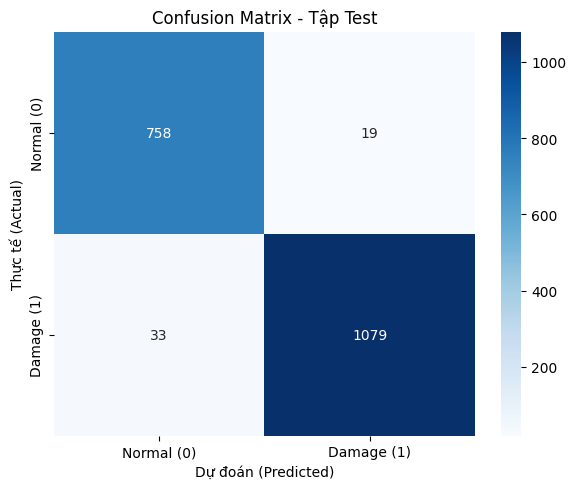

Đã lưu hình ảnh Confusion Matrix tại: /kaggle/working/confusion_matrix.png

⚙️ Đang xuất mô hình PyTorch (.pth)...
✅ Lưu hoàn tất tại: /kaggle/working/final_results.zip
Tải file zip về để nhận đầy đủ:
 1. Ảnh biểu đồ (training_history.png)
 2. Ảnh Confusion Matrix (confusion_matrix.png)
 3. File CSV lịch sử (training_history.csv)
 4. Trọng số tốt nhất (best_model.pth)
 5. Trọng số epoch cuối (last_model.pth)
 6. Trọng số export (packaging_model_weights.pth)
 7. Mô hình export đầy đủ (packaging_model_full.pth)


In [17]:
import zipfile
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Tải lại trọng số tốt nhất từ quá trình train
model.load_state_dict(torch.load(best_model_path))
model.eval()

t_preds, t_labels, t_probs = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        logits = model(x.to(DEVICE))
        t_probs.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
        t_preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
        t_labels.extend(y.numpy())

print("\n📊 --- KẾT QUẢ TẬP TEST ---")
print(f"Accuracy : {accuracy_score(t_labels, t_preds):.4f}")
print(f"Precision: {precision_score(t_labels, t_preds):.4f}")
print(f"Recall   : {recall_score(t_labels, t_preds):.4f}")
print(f"F1-Score : {f1_score(t_labels, t_preds):.4f}")
print(f"mAP (AP) : {average_precision_score(t_labels, t_probs):.4f}")

# Vẽ và lưu Confusion Matrix bằng Seaborn
cm = confusion_matrix(t_labels, t_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal (0)', 'Damage (1)'], 
            yticklabels=['Normal (0)', 'Damage (1)'])
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.title('Confusion Matrix - Tập Test')
plt.tight_layout()

cm_img_path = "/kaggle/working/confusion_matrix.png"
plt.savefig(cm_img_path, dpi=300)
plt.show()
print(f"Đã lưu hình ảnh Confusion Matrix tại: {cm_img_path}")

print("\n⚙️ Đang xuất mô hình PyTorch (.pth)...")
model.cpu().eval()

pth_weights_path = "/kaggle/working/packaging_model_weights.pth"
torch.save(model.state_dict(), pth_weights_path)

pth_full_path = "/kaggle/working/packaging_model_full.pth"
torch.save(model, pth_full_path)

zip_path = '/kaggle/working/final_results.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    # 1. Các file mô hình export ở cell này
    zipf.write(pth_weights_path, os.path.basename(pth_weights_path))
    zipf.write(pth_full_path, os.path.basename(pth_full_path))
    
    # 2. Các file mô hình từ cell train
    if os.path.exists(best_model_path):
        zipf.write(best_model_path, os.path.basename(best_model_path))
    if os.path.exists(last_model_path):
        zipf.write(last_model_path, os.path.basename(last_model_path))
        
    # 3. Lịch sử huấn luyện (Ảnh và CSV)
    history_img = "/kaggle/working/training_history.png"
    if os.path.exists(history_img):
        zipf.write(history_img, "training_history.png")
        
    csv_history = "/kaggle/working/training_history.csv"
    if os.path.exists(csv_history):
        zipf.write(csv_history, "training_history.csv")
        
    # 4. Ảnh Confusion Matrix
    if os.path.exists(cm_img_path):
        zipf.write(cm_img_path, "confusion_matrix.png")
        
print(f"✅ Lưu hoàn tất tại: {zip_path}")
print("Tải file zip về để nhận đầy đủ:")
print(" 1. Ảnh biểu đồ (training_history.png)")
print(" 2. Ảnh Confusion Matrix (confusion_matrix.png)")
print(" 3. File CSV lịch sử (training_history.csv)")
print(" 4. Trọng số tốt nhất (best_model.pth)")
print(" 5. Trọng số epoch cuối (last_model.pth)")
print(" 6. Trọng số export (packaging_model_weights.pth)")
print(" 7. Mô hình export đầy đủ (packaging_model_full.pth)")